# Access SARWAVE sea state

SARWAVE Sentinel-1 IW Level-2 products provide estimates of significant wave height and mean wave period from synthetic aperture radar observations, developed by Ifremer.

This example uses intraburst observations over the eastern Mediterranean from 23 to 26 January 2022, during Storm Elpis.

* Project resources: [SARWAVE](https://www.sarwave.org/resources)
* Original data source: [Ifremer 2022 Zarr archive](https://cerweb.ifremer.fr/datarmor/sarwave/diffusion/sar/iw/slc/l2/experimental_product_collection/v3.0/17.5km/uncompressed_zarr/2022/)
* Reference: [SARWAVE Sentinel-1 Experimental Dataset — Level-2 WAV](https://doi.org/10.12770/1b05fc41-e06e-4285-ad7b-b97f6f847e00)
* Product documentation: [SARWAVE Level-2 product description](https://cerweb.ifremer.fr/datarmor/sarwave/documentation/processor/sar/sarwaveifrproc/html/product_description.html)

In [1]:
import numpy as np
import xarray as xr

## Select region and time

Select 23–26 January 2022 in the eastern Mediterranean (23–37°E, 32.5–39°N).

In [2]:
interburst = xr.open_zarr("https://s3.waw4-1.cloudferro.com/EarthCODE/OSCAssets/sarwave/l2-2022/combined_sarwave-2022-interburst.zarr/")
intraburst = xr.open_zarr("https://s3.waw4-1.cloudferro.com/EarthCODE/OSCAssets/sarwave/l2-2022/combined_sarwave-2022-intraburst.zarr/")

ds = intraburst[["hs_most_likely", "land_flag", "center_lat", "center_lon"]].assign_coords(time=intraburst.source_sensing_start)
ds = ds.where(
    ((ds.time >= np.datetime64("2022-01-23"))
     & (ds.time < np.datetime64("2022-01-27"))
     & (ds.center_lon >= 23) & (ds.center_lon <= 37)
     & (ds.center_lat >= 32.5) & (ds.center_lat <= 39)).compute(),
    drop=True,
)
ds

<xarray.Dataset> Size: 49kB
Dimensions:         (source: 48, tile_line: 10, tile_sample: 5)
Coordinates:
  * source          (source) int32 192B 4026 4027 4028 4029 ... 4662 4663 4664
    time            (source) datetime64[ns] 384B 2022-01-23T04:15:11.482177 ....
  * tile_line       (tile_line) int32 40B 0 1 2 3 4 5 6 7 8 9
  * tile_sample     (tile_sample) int32 20B 0 1 2 3 4
Data variables:
    hs_most_likely  (source, tile_line, tile_sample) float64 19kB dask.array<chunksize=(48, 10, 5), meta=np.ndarray>
    land_flag       (source, tile_line, tile_sample) float32 10kB dask.array<chunksize=(48, 10, 5), meta=np.ndarray>
    center_lat      (source, tile_line, tile_sample) float32 10kB dask.array<chunksize=(48, 10, 5), meta=np.ndarray>
    center_lon      (source, tile_line, tile_sample) float32 10kB dask.array<chunksize=(48, 10, 5), meta=np.ndarray>
Attributes: (12/13)
    sarwave_layout_version:  2
    burst_group:             intraburst
    year:                    2022
    source_root:             /run/media/krasen/Storage/sarwave/ifremer-l2-sar...
    description:             Native full-year L2 SARWAVE grids padded on sour...
    source_order:            Sorted year/day/SAFE product path/subswath filen...
    ...                      ...
    padding:                 Floats NaN; integers dtype sentinel; valid_tile ...
    padding_scope:           Observed maxima from 65550 sources across all 20...
    reconstruction:          Crop each source; restore original variable dime...
    build_status:            verified_1000_random_sources
    written_sources:         65550
    verification_seed:       20261119

## Plot significant wave height

Select `hs_most_likely`, in metres, and mask tiles where `land_flag` is not zero. Plot using the scene’s latitude and longitude coordinates.

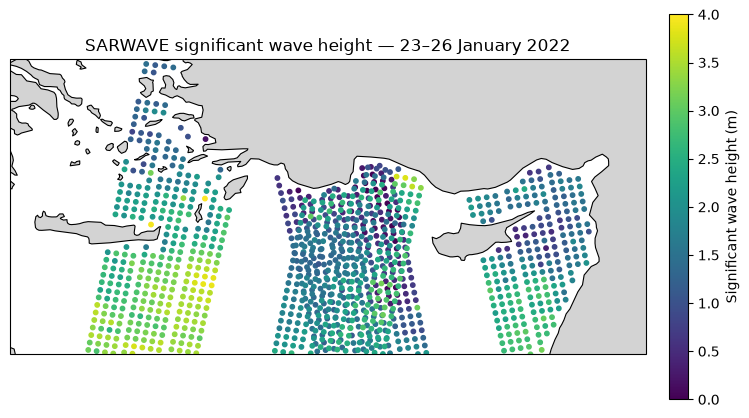

In [3]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

hs = ds.hs_most_likely.where(ds.land_flag == 0)

fig, ax = plt.subplots(figsize=(10, 5), subplot_kw={"projection": ccrs.PlateCarree()})
im = ax.scatter(
    ds.center_lon.values.ravel(), ds.center_lat.values.ravel(),
    c=hs.values.ravel(), s=10, cmap="viridis", vmin=0, vmax=4,
    transform=ccrs.PlateCarree(),
)
ax.set_extent([23, 37, 32.5, 39], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND.with_scale("50m"), facecolor="lightgray")
ax.coastlines("50m", linewidth=0.8)
fig.colorbar(im, ax=ax, label="Significant wave height (m)", pad=0.03)
ax.set_title("SARWAVE significant wave height — 23–26 January 2022")
plt.show()

## Scene statistics

Summarise significant wave height over the retained ocean tiles. Missing values are excluded.

In [4]:
hs.to_series().describe().round(2)

count    1131.00
mean        1.91
std         0.89
min         0.00
25%         1.33
50%         1.82
75%         2.58
max         4.05
Name: hs_most_likely, dtype: float64

## Daily wave statistics

Daily mean and maximum over the observed ocean tiles. Coverage varies by day.

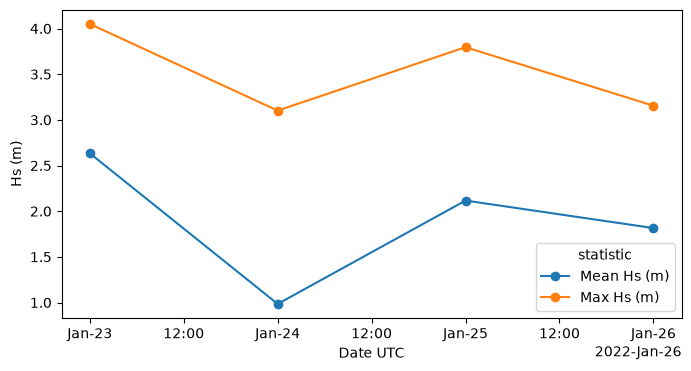

In [5]:
daily = hs.assign_coords(time=hs.time.dt.floor("D").compute()).groupby("time")
stats = xr.Dataset({
    "Mean Hs (m)": daily.mean(dim=["source", "tile_line", "tile_sample"]),
    "Max Hs (m)": daily.max(dim=["source", "tile_line", "tile_sample"]),
})

stats.to_array("statistic").plot.line(x="time", hue="statistic", marker="o", figsize=(8, 4))
plt.xlabel("Date UTC")
plt.ylabel("Hs (m)")
plt.show()

# Original Format Compatibility

To recreate the format of the original data you can run the snippet below

In [ ]:
ds = xr.open_zarr('https://s3.waw4-1.cloudferro.com/EarthCODE/OSCAssets/sarwave/l2-2022/combined_sarwave-2022-interburst.zarr/')
rnd_source = 20000

source_file = ds.source_id[rnd_source].values.item()

new_values = ds.sel(source=rnd_source).phs0_conf.values
new_values = new_values[: ds.sel(source=rnd_source).source_tile_lines.values, :ds.sel(source=rnd_source).source_tile_samples.values]

new_values

: 